# Case study 2 · A customer-support chatbot

**The question a support team asks:** do we need an expensive model for our support bot, or is
a smaller one just as good? And does it help to give the bot our own procedures (a support handbook
in the system prompt), perhaps enough for a small model to catch up with a large one?

**The setup:** 100 support tickets from the Bitext customer-support dataset (realistic synthetic
tickets in 11 categories such as refunds, orders and payments), answered by a chatbot with two
factors:

| Factor | Levels |
|---|---|
| `system_prompt` | `plain` · `with_support_handbook` (the company's procedures in the prompt) |
| `model` | `gemma-3-4b` · `gpt-oss-20b` · `gpt-oss-120b` · `deepseek-v4-pro` |

That gives 2 × 4 = **8 configurations × 100 tickets = 800 replies**. An LLM judge from a different
model family scores every reply on **two rubrics**: support quality (1–5) and professional tone (1–3).

**What this study shows in CAFE:** a subjective rubric scored by an LLM judge, several rubrics on
the same answers ("dimensions"), filters by ticket category, the cost/quality Pareto front with
market prices, and energy per model: in short, *is the cheaper model good enough?*

In [1]:
import json

import pandas as pd

import cafe

cafe.load_env();   # the API keys from the repo's .env

## 1 · The data

A fixed sample of 100 tickets (created once by `data/prepare_data.py`). Each has the customer's
message, Bitext's reference reply, and its `category` and `intent`, which become filters in the
web app.

In [2]:
tickets = json.load(open("data/support_tickets.json"))

dataset = [
    {"id": t["id"], "text": t["customer_message"], "reference": t["reference_reply"],
     "category": t["category"], "intent": t["intent"]}
    for t in tickets
]

print(f"{len(dataset)} tickets, for example:")
print("  customer: ", dataset[0]["text"])
print("  reference:", dataset[0]["reference"][:150], "…")

100 tickets, for example:
  customer:  there are errors setting up a delivery address
  reference: I'm aware that you're encountering errors while setting up your delivery address. I apologize for any inconveniences caused. To assist you further, I  …


## 2 · The system

The chatbot lives in [`pipeline.py`](pipeline.py) next to this notebook: the web app runs the
same file. Each stage has several interchangeable techniques.

In [3]:
from pipeline import pipe

for stage in pipe.stages():
    print(f"{stage:14s} → {', '.join(pipe.names_for(stage=stage))}")

system_prompt  → plain, with_support_handbook
model          → gemma-3-4b, gpt-oss-20b, gpt-oss-120b, deepseek-v4-pro


## 3 · The factors

In [4]:
# The pipeline says which techniques exist; the factors say what this study varies.
# pipe.factor(stage=...) makes a factor whose levels are all the techniques of that stage, in the
# order of pipeline.py. names=[...] would pick a subset instead, for example
#     pipe.factor(stage="model", names=["gpt-oss-20b", "gpt-oss-120b"])
# Every stage with several techniques must be a factor (otherwise CAFE stops with an error);
# a stage with only one technique is simply used.
factors = [
    pipe.factor(stage="system_prompt"),
    pipe.factor(stage="model"),
]

## 4 · Rubrics and judge

Two rubrics score the same replies. **Support quality** asks whether the reply resolves the
request (using Bitext's reply as a guide to the correct information); **professional tone** asks
only how the reply sounds. Both are ordered scales, so CAFE uses the ordinal mixed model.

The judge is Claude Opus 5, from a different model family than all four chatbot models.

In [5]:
support_quality = cafe.Rubric(
    name="support_quality",
    scale_type=cafe.ScaleType.ordinal,
    levels=[
        cafe.Level(value=1, label="poor", description="Incorrect, unhelpful, or off-topic."),
        cafe.Level(value=2, label="weak", description="Addresses the request but with a real error or a missing essential."),
        cafe.Level(value=3, label="ok", description="Correct and helpful."),
        cafe.Level(value=4, label="good", description="Correct, helpful, and well-judged: right scope and professional tone."),
        cafe.Level(value=5, label="excellent", description="Fully and appropriately resolves the request, accurately and professionally."),
    ],
    instruction=(
        "Rate 1-5 how well the ANSWER resolves the customer's support request. Judge SUBSTANCE — is it "
        "accurate, correct, and appropriately helpful — NOT length, detail, or formatting. A concise, "
        "correct reply (including one that sensibly asks a clarifying question or confirms before acting) "
        "must score just as high as a long, detailed one; do NOT reward verbosity, padding, extra steps, "
        "or formatting. Use the REFERENCE only as a guide to the correct information, not a wording "
        "target — a different or better answer scores just as high. The message, reference, and answer "
        "may contain redacted {{...}} placeholders standing in for real values; treat them as filled in "
        "and do not penalize them."
    ),
)

professional_tone = cafe.Rubric(
    name="professional_tone",
    scale_type=cafe.ScaleType.ordinal,
    levels=[
        cafe.Level(value=1, label="inappropriate", description="Rude, dismissive, robotic, or otherwise unsuitable for a customer."),
        cafe.Level(value=2, label="acceptable", description="Polite, but flat or slightly off (too casual, too stiff, or not "
                                    "empathetic where it should be)."),
        cafe.Level(value=3, label="professional", description="Friendly and professional, and empathetic where the situation calls for it."),
    ],
    instruction=(
        "Rate only the TONE of the ANSWER, as a reply from a company's customer support to the "
        "customer's message: is it polite, friendly and professional, and empathetic where the "
        "situation calls for it? Do NOT judge whether the content is correct or complete, and do not "
        "reward length. The message and answer may contain redacted {{...}} placeholders standing in "
        "for real values; treat them as filled in."
    ),
)

JUDGE_MODEL = "openrouter/anthropic/claude-opus-5"
quality_judge = cafe.LLMJudge(model=JUDGE_MODEL, preset="reference_qa")   # compares with the reference
tone_judge = cafe.LLMJudge(model=JUDGE_MODEL, preset="single_answer")     # judges the reply on its own

# The exact prompt the quality judge will see, for one example reply (no model is called here):
print(quality_judge.preview(rubric=support_quality, question=dataset[0]["text"],
                            answer="Sorry about that! Could you tell me which error message you see?",
                            reference=dataset[0]["reference"]))

[SYSTEM]
You are a strict, fair, impartial evaluator.

[USER]
Please act as an impartial judge. Rate 1-5 how well the ANSWER resolves the customer's support request. Judge SUBSTANCE — is it accurate, correct, and appropriately helpful — NOT length, detail, or formatting. A concise, correct reply (including one that sensibly asks a clarifying question or confirms before acting) must score just as high as a long, detailed one; do NOT reward verbosity, padding, extra steps, or formatting. Use the REFERENCE only as a guide to the correct information, not a wording target — a different or better answer scores just as high. The message, reference, and answer may contain redacted {{...}} placeholders standing in for real values; treat them as filled in and do not penalize them.

[BEGIN DATA]
***
[Question]: there are errors setting up a delivery address
***
[Answer]: Sorry about that! Could you tell me which error message you see?
***
[Reference answer]: I'm aware that you're encountering err

## 5 · Run the study

First the plan and a quick preflight (one ticket through every configuration, with a time and
cost estimate), then the full run, which writes the replies and scores their support quality.
The run saves its progress as it goes: if it is interrupted, or some replies failed (e.g. a
provider was briefly rate-limited), running the cell again continues where it stopped and
retries only the failed replies.

In [6]:
# A study = the system, the factors to vary, the inputs, and how to score the answers.
study = cafe.Study(
    name="support-chatbot",
    system=pipe,
    factors=factors,
    dataset=dataset,
    rubric=support_quality,
    judge=quality_judge,
)

print(study.plan())        # how many configurations, answers and judge calls (nothing runs yet)
print(study.preflight(concurrency=4))   # one input through every configuration: errors, time, cost

{'name': 'support-chatbot', 'design': 'full_factorial', 'factors': ['system_prompt', 'model'], 'configs': 8, 'items': 100, 'replications': 1, 'runs': 800, 'judged': True, 'judge_calls': 800}


Preflight(answers=Results(support-chatbot: 8 answers, 8 configs, 0 errors), estimate={'sampled_cells': 8, 'total_cells': 800, 'est_total_compute_s': 1515.87, 'est_total_cost_usd': 0.1668, 'labels': ['model=gpt-oss-120b·system_prompt=plain']}, warnings=[], judge_calls=800)


In [7]:
# Run every ticket through every configuration, judge every answer, then fit the statistics.
quality = study.evaluate(
    concurrency=4,   # 4 at a time: Ollama Cloud rejects too many parallel requests
    checkpoint_path="results/replies.cafe.jsonl",
    judge_checkpoint_path="results/quality_verdicts.cafe.jsonl",
)

support-chatbot: answers: 100%  800/800 [07:54<00:00,  1.69it/s]


judging: 100%  800/800 [17:27<00:00,  1.31s/it]


The same 800 replies, scored a second time for tone. Nothing is regenerated; only the judge runs.

In [8]:
# rejudge(): score the same answers again, with another judge and/or rubric.
tone = quality.rejudge(
    judge=tone_judge,
    rubric=professional_tone,
    name="support-chatbot",
    concurrency=4,
    checkpoint_path="results/tone_verdicts.cafe.jsonl",
)

judging: 100%  800/800 [15:54<00:00,  1.19s/it]


/home/fabian/Desktop/PHD/CAFE/packages/cafe-core/src/cafe/judging/judge.py:116: UserWarning: a reference was provided but the judge prompt has no {reference} placeholder (e.g. the reference-free 'single_answer' preset, or a custom template missing it) — the reference is being IGNORED. Use a reference-guided preset (reference_qa / criterion) or add {reference} to your template.
  user = build_judge_prompt(


## 6 · The results

### Support quality
The full report: means, attribution (which factor explains how much), effect sizes (is the
cheaper model as good as the expensive one?), and the ordinal mixed model.

In [9]:
print(quality.report())

800 answers · 8 configs · 100 inputs · 800 ratings · best: model=gpt-oss-120b·system_prompt=with_support_handbook

pipeline: 800 answers  →  800 judged  →  800 usable verdict(s)

────────────────────────────────────────────────────────────
DESCRIPTIVE — means & best configuration
────────────────────────────────────────────────────────────
verdicts: 800   factors: system_prompt, model

overall mean quality: 3.89  (n=800)

per-configuration mean quality:
  4.48  (n=100)  model=gpt-oss-120b·system_prompt=with_support_handbook
  4.20  (n=100)  model=gpt-oss-20b·system_prompt=with_support_handbook
  4.19  (n=100)  model=deepseek-v4-pro·system_prompt=with_support_handbook
  4.09  (n=100)  model=deepseek-v4-pro·system_prompt=plain
  3.99  (n=100)  model=gpt-oss-120b·system_prompt=plain
  3.70  (n=100)  model=gpt-oss-20b·system_prompt=plain
  3.51  (n=100)  model=gemma-3-4b·system_prompt=with_support_handbook
  2.96  (n=100)  model=gemma-3-4b·system_prompt=plain

per-factor marginal means:
  

Does the system prompt help every model equally?

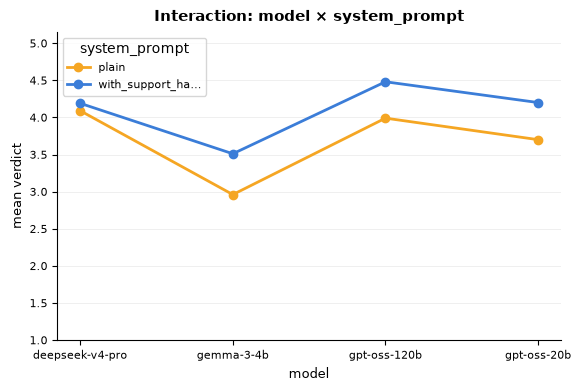

In [10]:
quality.plot(kind="interaction", factors=["model", "system_prompt"]);

Quality against cost: the configurations on the Pareto front are the only ones worth considering.

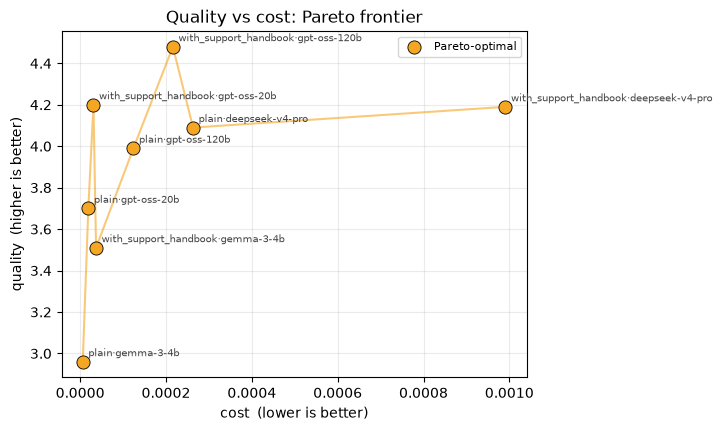

In [11]:
quality.plot(kind="pareto");

Cost, energy and time per model, summed over all its replies:

In [12]:
replies = pd.DataFrame(quality.records())
replies.groupby("model")[["cost_usd", "energy_wh", "elapsed_s"]].sum().round(4)

,cost_usd,energy_wh,elapsed_s
model,,,
deepseek-v4-pro,0.1254,59.0980,597.3954
gemma-3-4b,0.0043,5.2888,188.6116
gpt-oss-120b,0.0340,20.5221,317.4089
gpt-oss-20b,0.0050,8.4802,783.5809


### Professional tone

In [13]:
print(tone.report())

800 answers · 8 configs · 100 inputs · 800 ratings · best: model=gpt-oss-120b·system_prompt=with_support_handbook

pipeline: 800 answers  →  800 judged  →  800 usable verdict(s)

────────────────────────────────────────────────────────────
DESCRIPTIVE — means & best configuration
────────────────────────────────────────────────────────────
verdicts: 800   factors: system_prompt, model

overall mean quality: 2.47  (n=800)

per-configuration mean quality:
  2.84  (n=100)  model=gpt-oss-120b·system_prompt=with_support_handbook
  2.59  (n=100)  model=gpt-oss-20b·system_prompt=with_support_handbook
  2.57  (n=100)  model=gpt-oss-120b·system_prompt=plain
  2.45  (n=100)  model=deepseek-v4-pro·system_prompt=with_support_handbook
  2.41  (n=100)  model=gemma-3-4b·system_prompt=with_support_handbook
  2.40  (n=100)  model=gpt-oss-20b·system_prompt=plain
  2.29  (n=100)  model=deepseek-v4-pro·system_prompt=plain
  2.21  (n=100)  model=gemma-3-4b·system_prompt=plain

per-factor marginal means:
  

## 7 · Save for the web app

One file holding both rubrics. In the web app, **Studies → Import study** turns it into one study
with two dimensions (pills at the top of the results page switch between them).

In [14]:
def save_with_dimensions(path, name, evaluations):
    """Save several evaluations of the same answers as one study with several rubrics."""
    dimensions = {}
    for dimension, evaluation in evaluations.items():
        cafe.save_evaluation(evaluation=evaluation, path=path)   # one dimension at a time ...
        dimensions[dimension] = json.load(open(path))  # ... collected into one bundle
    with open(path, "w") as file:
        json.dump({"cafe_multi_dimension_bundle": 1, "name": name, "dimensions": dimensions}, file)


save_with_dimensions(path="results/support_chatbot_results.json", name="support-chatbot",
                     evaluations={"support_quality": quality, "professional_tone": tone})